In [12]:
import numpy as np
import pandas as pd
import time
import json
import matplotlib.pyplot as plt
from pathlib import Path
import ollama
from utils import downsample, squashOneHots, truncateDecimals
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import classification_report, confusion_matrix

In [13]:
train,valid,test = pd.read_csv("data/train.csv"),pd.read_csv("data/valid.csv"),pd.read_csv("data/test.csv")

train = downsample(train, N=6000)
valid = downsample(valid, N=2000)
test = downsample(test, N=2000)

X_train, y_train = train.drop(columns="class"), train["class"]
X_valid, y_valid = valid.drop(columns="class"), valid["class"]
X_test, y_test = test.drop(columns="class"), test["class"]

# Nearest Neighbors Shenanigans

In [14]:
# Gets nearest neighbors to "point" from among the "data" dataset, excluding class
# Uses weights for one-hot columns to avoid heavy weighting

def getNearestNeighbors(data, point, N=25, soil_weight=0.50, wilderness_weight=0.50):
    data = data.drop(columns=["class"],errors="ignore")
    point = point.drop(columns=["class"],errors="ignore")

    for i in range(1,40+1):
        data["Soil_Type"+str(i)] *= soil_weight
        point["Soil_Type"+str(i)] *= soil_weight

    for j in range(1,4+1):
        data["Wilderness_Area"+str(j)] *= wilderness_weight
        point["Wilderness_Area"+str(j)] *= wilderness_weight

    nn = NearestNeighbors(n_neighbors=N, metric="euclidean")
    nn.fit(data)

    distances, indices = nn.kneighbors(point)

    nearest_df = data.iloc[indices[0]].copy()
    nearest_df["distance"] = distances[0]

    return nearest_df

In [15]:
nearest_df = getNearestNeighbors(
    train,
    train.iloc[[0]],
    N = 25,
    soil_weight = 0.5,
    wilderness_weight = 0.5
)

In [16]:
def generateKnnPromptForPoint(X_train,y_train,test_point,N=25,filename="knn_prompt.txt"):

    dataset_size = len(X_train)

    assert(len(X_train) == len(y_train))
    assert(len(test_point)==1)

    nearest_df = getNearestNeighbors(
        X_train,
        test_point,
        N = N,
        soil_weight = 0.5,
        wilderness_weight = 0.5
    )

    nearest_df["class"] = y_train.loc[nearest_df.index]

    nearest_df = squashOneHots(nearest_df)
    nearest_df = truncateDecimals(nearest_df,digits=4)

    test_point = squashOneHots(test_point)
    test_point = truncateDecimals(test_point,digits=4)

    output_string = f"""
        You are tasked with identifying a tree's class / variety based on a variety of factors,
        including soil type, wilderness area, hillshade, distance to certain geological features, and local topography.

        You are given the features of one "test tree" (without the class label), as well as the features and classes of
        the top {N} trees (from a dataset of tens of thousands of trees), as measured by feature distance to the chosen test tree.

        Your task is to simply output one number, from 1 to 7, corresponding to the class you believe the tree belongs to.
        DO NOT simply perform a K-nearest-neighbors plurality. Use your world knowledge, general reasoning, and observations from the data
        to make an informed conclusion.

        {N} nearest neighbors:

        {nearest_df.to_csv()}

        Unclassified point:

        {test_point.to_csv()}

        Now, enter the class number (1 to 7) here. Your response should be a single number, with no additional text or formatting.
    """
    
    file = open(f"./prompts/{filename}","w")
    file.write(output_string)
    file.close()

    return output_string, nearest_df

In [17]:
def getMode(df):
    class_col = df["class"]
    ls = class_col.mode().tolist()
    formatted = ",".join([str(int(x)) for x in ls])
    return ls[0],formatted

In [18]:
def recordResults(K,N_train,N_test,model,acc,avg_prec,avg_rec,avg_f1,knn_acc,knn_avg_prec,knn_avg_rec,knn_avg_f1):
    file_path = Path("data/aggregate_llm_results.csv")

    df = None

    if file_path.is_file():
        df = pd.read_csv(file_path)

    else:
        df = pd.DataFrame(columns=["K","N_train","N_test","model","acc","avg_prec","avg_rec","avg_f1","knn_acc","knn_avg_prec","knn_avg_rec","knn_avg_f1"]) # not yet mult. by 7!!!

    new_row = pd.DataFrame([{
        "K": K,
        "N_train": N_train,
        "N_test": N_test,
        "model": model,

        "acc": acc,
        "avg_prec": avg_prec,
        "avg_rec": avg_rec,
        "avg_f1": avg_f1,

        "knn_acc": knn_acc,
        "knn_avg_prec": knn_avg_prec,
        "knn_avg_rec": knn_avg_rec,
        "knn_avg_f1": knn_avg_f1
    }])

    df = pd.concat([df,new_row], ignore_index=True)

    df.to_csv(file_path,index=False)

In [19]:
def fullKnnTest(K=25,N_train=2000,N_test=15,model="gemma4:12b",experiment_name=False,include_in_aggregate=False,verbose=False):

    train2,test2 = pd.read_csv("data/train.csv"),pd.read_csv("data/test.csv")

    train2 = downsample(train2, N=N_train)
    test2 = downsample(test2, N=N_test)

    X_train, y_train = train2.drop(columns="class"), train2["class"]
    X_test, y_test = test2.drop(columns="class"), test2["class"]

    print(f"Proceeding with LLM-guided KNN test with K={K} neighbors, {len(X_train)} training examples, and {len(X_test)} test instances, using {model} via Ollama.")

    t0 = time.time()
    tL = time.time()

    iter_count = len(X_test)

    results = []

    for i in range(len(X_test)):
        if verbose:
            print(f"Beginning iteration {i+1} of {iter_count} ({(i/iter_count)*100:.1f}% complete)...")

        test_point = X_test.iloc[[i]]

        prompt_filename = f"knn_prompt_{i}.txt"

        test_prompt, nearest_df = generateKnnPromptForPoint(
            X_train,
            y_train,
            test_point,
            N = K,
            filename = prompt_filename
        )

        response = ollama.chat(
            model=model,
            messages=[{'role': 'user', 'content': test_prompt}],
            format={
                "type": "object",
                "properties": {
                    "class": {
                        "type": "integer",
                        "enum": [1,2,3,4,5,6,7]
                    }
                },
                "required": ["class"],
                "additionalProperties": False,
            },
            think=False,
            stream=False,
            options={"temperature":0},
        )

        #content = response['message']['content'].strip()
        llm_class = json.loads(response.message.content)["class"]

        #predicted_class = int(content) if content.isdigit() else -1
        #if predicted_class > 7:
            #predicted_class = -2

        true_class = int(y_test.iloc[i])

        mode_class,mode_str = getMode(nearest_df)

        results.append([llm_class,true_class,mode_class,mode_str])

        ti = time.time()
        if verbose:
            print(f"Completed iteration {i+1} in {ti-tL:.2f}s ({ti-t0:.2f}s total)")
        tL = ti
    
    column_labels = ["predicted_class","actual_class", "mode_class", "mode_str"]
    df = pd.DataFrame(results,columns=column_labels)

    total_duration = time.time()-t0
    print(f"Successfully completed all iterations in {total_duration:.2f} seconds.")

    if not experiment_name:
        experiment_name = f"llm_k-{K}_train-{N_train}_test-{N_test}_model-{model.replace(":","")}_t-{int(total_duration)}s"

    # Dump raw results
    df.to_csv(f"data/llm_experiments/{experiment_name}_raw.csv", index=False)

    # Summary statistics...

    labels = sorted(df['actual_class'].unique())

    cm = confusion_matrix(df["actual_class"], df["predicted_class"], labels=labels)

    cm_df = pd.DataFrame(
        cm,
        index=[f'actual_{l}' for l in labels],
        columns=[f'pred_{l}' for l in labels]
    )

    print("Confusion matrix:\n")
    print(cm_df)

    report = classification_report(df["actual_class"], df["predicted_class"])

    print("\n\n\nClassification Report:\n")
    print(report)

    print(f"Saved results in data/llm_experiments/{experiment_name}_[raw/report].[csv,txt]")

    with open(f"data/llm_experiments/{experiment_name}_report.txt","w",encoding="utf-8") as file:
        file.write(report)


    report_dict = classification_report(df["actual_class"], df["predicted_class"], output_dict=True)
    knn_report_dict = classification_report(df["actual_class"],df["mode_class"], output_dict=True)

    if include_in_aggregate:
        recordResults(
            K=K,
            N_train=N_train,
            N_test=N_test,
            model=model,

            acc=report_dict["accuracy"],
            avg_prec=report_dict["macro avg"]["precision"],
            avg_rec=report_dict["macro avg"]["recall"],
            avg_f1=report_dict["macro avg"]["f1-score"],

            knn_acc=knn_report_dict["accuracy"],
            knn_avg_prec=knn_report_dict["macro avg"]["precision"],
            knn_avg_rec=knn_report_dict["macro avg"]["recall"],
            knn_avg_f1=knn_report_dict["macro avg"]["f1-score"]
        )

    return df
    

In [20]:
TIME_START = time.time()

for K in [1,3,5,11,25,51,99]:
    for N_train in [100,500,1000,2000]:
        results = fullKnnTest(
            K=K,
            N_train=N_train, # times 7
            N_test=50, # times 7
            model="gemma4:12b",
            experiment_name=False, # don't commit to a name
            include_in_aggregate=True, # record summary statistics
            verbose=False
)

TIME_END = time.time()

print(f"TOTAL TIME ELAPSED: {TIME_END-TIME_START:.1f} seconds ({(TIME_END-TIME_START)/3600:.2f}) hours")

Proceeding with LLM-guided KNN test with K=1 neighbors, 700 training examples, and 350 test instances, using gemma4:12b via Ollama.
Successfully completed all iterations in 296.59 seconds.
Confusion matrix:

          pred_1  pred_2  pred_3  pred_4  pred_5  pred_6  pred_7
actual_1      23      11       3       0       9       0       4
actual_2      13      22       3       1      10       1       0
actual_3       0       4      28       2       3      13       0
actual_4       0       0       2      41       0       7       0
actual_5       3       3       4       0      38       1       1
actual_6       2       3      14       4       0      27       0
actual_7       3       1       3       0       1       0      42



Classification Report:

              precision    recall  f1-score   support

           1       0.52      0.46      0.49        50
           2       0.50      0.44      0.47        50
           3       0.49      0.56      0.52        50
           4       0.85     

/home/everett/CISC684/CISC_684_Project/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/everett/CISC684/CISC_684_Project/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/everett/CISC684/CISC_684_Project/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(

Successfully completed all iterations in 723.07 seconds.
Confusion matrix:

          pred_1  pred_2  pred_3  pred_4  pred_5  pred_6  pred_7
actual_1      26       3      11       0       4       0       6
actual_2      30       7      12       0       0       1       0
actual_3      16       0      26       6       0       2       0
actual_4       3       1       2      42       0       2       0
actual_5      16       1      31       0       2       0       0
actual_6      20       0      22       6       0       2       0
actual_7      23       1      11       0       0       0      15



Classification Report:

              precision    recall  f1-score   support

           1       0.19      0.52      0.28        50
           2       0.54      0.14      0.22        50
           3       0.23      0.52      0.32        50
           4       0.78      0.84      0.81        50
           5       0.33      0.04      0.07        50
           6       0.29      0.04      0.07        5

In [21]:
results

,predicted_class,actual_class,mode_class,mode_str
0,4,4,4.0,4
1,7,7,7.0,7
2,1,7,7.0,7
3,1,5,5.0,5
4,4,4,4.0,4
...,...,...,...,...
345,2,2,1.0,1
346,3,3,3.0,3
347,1,6,6.0,6
348,1,7,7.0,7


In [22]:
report = classification_report(results["predicted_class"],results["actual_class"],output_dict=True)

In [23]:
print(report["macro avg"].keys())

dict_keys(['precision', 'recall', 'f1-score', 'support'])


In [27]:
aggregate_results = pd.read_csv("data/aggregate_llm_results.csv")

## LLM results by K-value

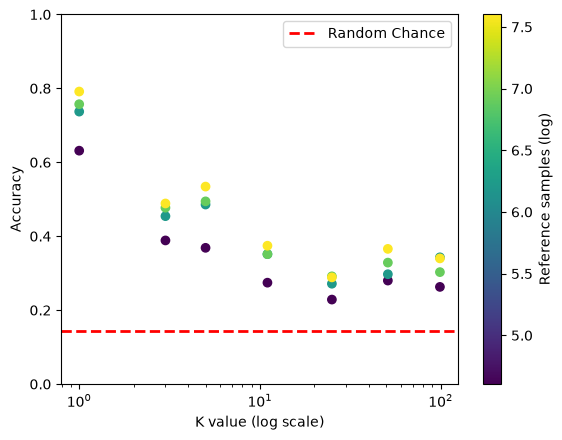

In [55]:
scatter = plt.scatter(
    aggregate_results["K"],
    aggregate_results["acc"],
    c=np.log(aggregate_results["N_train"]),
    cmap="viridis",
)

plt.colorbar(scatter,label="Reference samples (log)")

plt.xscale("log")
plt.ylim(0,1)
plt.axhline(y=1/7, color="r", linestyle="--", linewidth=2, label="Random Chance")
plt.xlabel("K value (log scale)")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

## LLM results by Reference Set Size

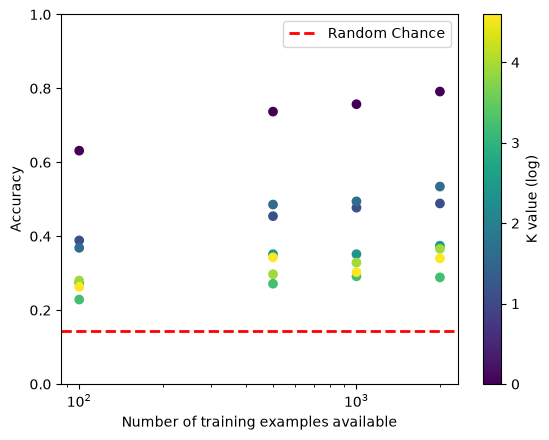

In [56]:
scatter = plt.scatter(
    aggregate_results["N_train"],
    aggregate_results["acc"],
    c=np.log(aggregate_results["K"]),
    cmap="viridis"
)

plt.colorbar(scatter,label="K value (log)")

plt.xscale("log")
plt.ylim(0,1)
plt.axhline(y=1/7, color="r", linestyle="--", linewidth=2, label="Random Chance")
plt.xlabel("Number of training examples available")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

## KNN Results by K-Value

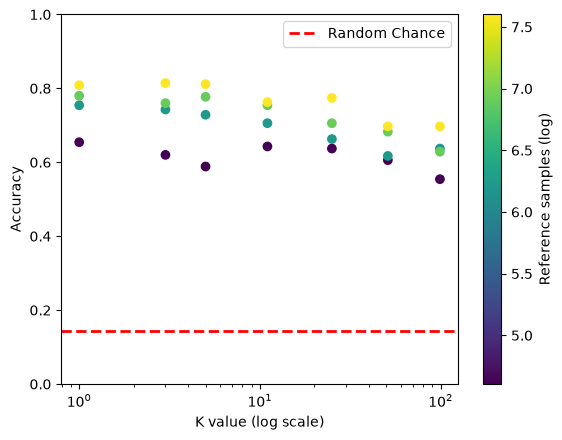

In [57]:
scatter = plt.scatter(
    aggregate_results["K"],
    aggregate_results["knn_acc"],
    c=np.log(aggregate_results["N_train"]),
    cmap="viridis",
)

plt.colorbar(scatter,label="Reference samples (log)")

plt.xscale("log")
plt.ylim(0,1)
plt.axhline(y=1/7, color="r", linestyle="--", linewidth=2, label="Random Chance")
plt.xlabel("K value (log scale)")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

## KNN Results by Reference Set Size

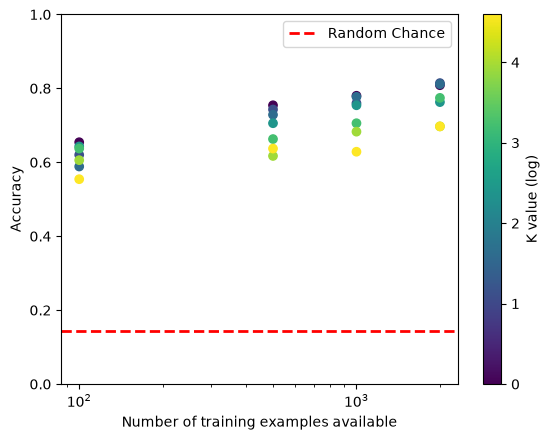

In [58]:
scatter = plt.scatter(
    aggregate_results["N_train"],
    aggregate_results["knn_acc"],
    c=np.log(aggregate_results["K"]),
    cmap="viridis"
)

plt.colorbar(scatter,label="K value (log)")

plt.xscale("log")
plt.ylim(0,1)
plt.axhline(y=1/7, color="r", linestyle="--", linewidth=2, label="Random Chance")
plt.xlabel("Number of training examples available")
plt.ylabel("Accuracy")
plt.legend()

plt.show()